<a href="https://colab.research.google.com/github/CalogeroGabriele/Artificial-Intelligence/blob/main/Supervised-Learning/Multivariate_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
import matplotlib.pyplot as plt
import numpy as np

In [66]:
np.random.seed(24)
m = 2000 #Number of examples
n = 2 #Number of features
X = 2 * np.random.rand(m,n)

#Valori reali (corretti) tetha che l'algoritmo di machine learning dovrà approssimare
theta = np.array([[3], [5]])
print(f"Contenuto theta: \n{theta}\n")
#Una normale lista come: theta = [3,5] avrebbe dimensioni (2,) , sarebbe ovvero monodimensionale
#ed inutilizzabile per il calcolo matriciale
print(f"Shape di theta: {theta.shape}\n")

#Questa non viene usata, è solo per dimostrare come scrivere una matrice anzichè un vettore (2,1) come quello soprastante
esempio_matrice = np.array([[1,2,3],[4,5,6]])
print(f"Contenuto matrice esempio: \n{esempio_matrice}\n")
print(f"Shape matrice: {esempio_matrice.shape}\n")

Y = 4 + X @ theta + 0.7*np.random.randn(m,1)
real_Y = 4 + X @ theta

print(f"\nContenuto Y con rumore: \n{Y}")

Contenuto theta: 
[[3]
 [5]]

Shape di theta: (2, 1)

Contenuto matrice esempio: 
[[1 2 3]
 [4 5 6]]

Shape matrice: (2, 3)


Contenuto Y con rumore: 
[[14.80990224]
 [11.64288596]
 [13.94519322]
 ...
 [17.31273467]
 [ 7.10862462]
 [16.66171744]]


/tmp/ipykernel_1888/2563687531.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


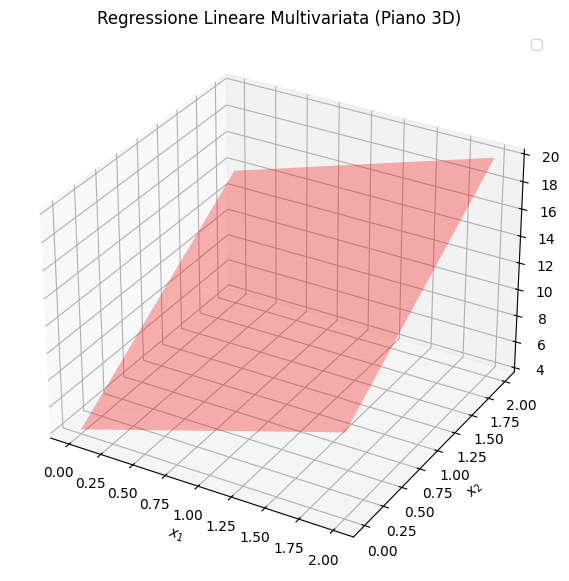

In [71]:
# 1. Creazione dell'ambiente 3D
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# 2. Punti campionati (blu)
#ax.scatter(X[:, 0], X[:, 1], Y, color="b", marker="o", label="Dati rumorosi Y")

# 3. Costruzione della griglia per il piano ideale real_Y (senza zig-zag)
x1_grid = np.linspace(0, 2, 20)
x2_grid = np.linspace(0, 2, 20)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)

# Equazione del piano teorico: y = 4 + 3*x1 + 5*x2
Y_plane = 4 + 3 * X1_mesh + 5 * X2_mesh

# Disegno del piano ideale trasparente (rosso)
ax.plot_surface(X1_mesh, X2_mesh, Y_plane, color="r", alpha=0.3)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$y$")
ax.set_title("Regressione Lineare Multivariata (Piano 3D)")
ax.legend()

plt.show()

In [68]:
#Lavorando con tre theta (per via del bias) è necessario che il primo valore di X (campioni in input) sia 1
X_b = np.c_[np.ones((m, 1)), X]
print(f"Vettore X con 1 come valore iniziale per ognuna delle righe:\n {X_b}\n")
print(f"Shape di X_b: {X_b.shape}\n")

# Bias , theta1, theta2
initial_thetas = np.array([[0],[0],[0]])
print(f"Shape di initial_thetas: {initial_thetas.shape}\n")

print("X*theta => (5,3)*(3,1) = (5,1)")

Vettore X con 1 come valore iniziale per ognuna delle righe:
 [[1.         1.92003461 1.3990241 ]
 [1.         1.99973459 0.4401346 ]
 [1.         0.72211271 1.47968198]
 ...
 [1.         1.98059067 1.35184805]
 [1.         0.02195227 0.71424013]
 [1.         1.28475018 1.83275471]]

Shape di X_b: (2000, 3)

Shape di initial_thetas: (3, 1)

X*theta => (5,3)*(3,1) = (5,1)


In [69]:
#Equazione normale (forma normale) - GUARDARE LA SEMPLIFICAZIONE DELL'EQUAZIONE DALLE SLIDES
def MSE(X, thetas, Y):
  errors = X_b @ thetas - Y
  #Item permetti di ritornare solo il valore del MSE come scalare anzichè come elemento di un array numpy
  #Funziona solo se l'array contiene esattamente un elemento
  return ((errors.T @ errors)/len(X_b)).item()

MSE(X_b,initial_thetas, Y)

153.7792549873524

In [70]:
#Normal equation per trovare i valori theta

#Il calcolo dell inversa ha complessità computazionale pari a O(n^3), operazione proibitiva per un altro numero di features (n> 10.000)
final_theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y

print(final_theta)

[[3.95511483]
 [3.02357861]
 [5.01035734]]
